# Phase 2 — EDA + Preprocessing (Vietnamese Books)
Notebook nay giup ban chay EDA va tao du lieu da xu ly cho retrieval. Hay chay tung cell theo thu tu.

## 1) Cai dat va kiem tra thu vien can thiet
Neu chua co, ban co the cai dat trong terminal. Notebook nay chi import va kiem tra phien ban.

In [ ]:
#read csv


In [23]:
import sys
import os
from pathlib import Path
import json

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 140)

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
pandas: 2.3.3
numpy: 2.2.6


## 2) Tai/doc du lieu mau
Doc file CSV tu data/raw/books.csv va xem nhanh schema.

In [24]:
data_path = Path("data/raw/books.csv")


def read_csv_fallback(path: Path) -> pd.DataFrame:
    encodings = ["utf-8", "utf-8-sig", "latin1"]
    last_error = None
    for enc in encodings:
        try:
            return pd.read_csv(path, encoding=enc)
        except Exception as exc:
            last_error = exc
    raise last_error


df_raw = read_csv_fallback(data_path)
df_raw.drop(columns=["tac_gia"], inplace=True)
print("Shape:", df_raw.shape)
print("Columns:", list(df_raw.columns))

df_raw.head(50000)

Shape: (30431, 17)
Columns: ['title', 'description', 'price', 'author', 'category', 'rating', 'thumbnail', 'ma_hang', 'ten_nha_cung_cap', 'nguoi_dich', 'nxb', 'nam_xb', 'ngon_ngu', 'trong_luong_gr', 'so_trang', 'hinh_thuc', 'source_url']


,title,description,price,author,category,rating,thumbnail,ma_hang,ten_nha_cung_cap,nguoi_dich,nxb,nam_xb,ngon_ngu,trong_luong_gr,so_trang,hinh_thuc,source_url
0,"1,2,3,5 Bữa - Nói Tóm Lại Ăn Thế Nào Là Tốt",1 bữa 1 ngày 2 bữa 1 ngày 5 bữa 1 ngày BẠN ĐAN...,79000,Woo Won Yang,Y học,5,https://cdn1.fahasa.com/media/catalog/product/...,8935280902534,Thái Hà,Nguyệt Minh,NXB Thế Giới,2019.0,NaN,317.0,269.0,Bìa Mềm,https://www.fahasa.com/1-2-3-5-bua-noi-tom-lai...
1,Hình Dán Sticker Và Tô Màu - Tập 6,Hình Dán Sticker Và Tô Màu - Tập 6 Hình Dán St...,18000,Trần Ngọc Bảo Hân,"Tô màu, luyện chữ",5,https://cdn1.fahasa.com/media/catalog/product/...,8935072958428,Cty Văn Hóa Nhân Văn,NaN,Thanh Hóa,2025.0,NaN,100.0,20.0,Bìa Mềm,https://www.fahasa.com/1-2-4-14-153-637350.html
2,Hình Dán Sticker Và Tô Màu - Tập 10,Hình Dán Sticker Và Tô Màu - Tập 10 Hình Dán S...,18000,Trần Ngọc Bảo Hân,"Tô màu, luyện chữ",5,https://cdn1.fahasa.com/media/catalog/product/...,8935072958466,Cty Văn Hóa Nhân Văn,NaN,Thanh Hóa,2025.0,NaN,100.0,20.0,Bìa Mềm,https://www.fahasa.com/1-2-4-14-153-637354.html
3,Hình Dán Sticker Và Tô Màu - Tập 1,Hình Dán Sticker Và Tô Màu - Tập 1 Hình Dán St...,18000,Trần Ngọc Bảo Hân,"Tô màu, luyện chữ",5,https://cdn1.fahasa.com/media/catalog/product/...,8935072958374,Cty Văn Hóa Nhân Văn,NaN,Thanh Hóa,2025.0,NaN,100.0,20.0,Bìa Mềm,https://www.fahasa.com/1-2-4-14-153.html
4,Khám Phá Thế Giới Khủng Long - Những Bí Ẩn Thờ...,Khám Phá Thế Giới Khủng Long - Những Bí Ẩn Thờ...,91000,Jackie Nguyễn,Tạp Chí Thiếu Nhi,5,https://cdn1.fahasa.com/media/catalog/product/...,8936065773356,CÔNG TY TNHH IN THƯƠNG MẠI TUẤN VIỆT,NaN,Đồng Nai,2024.0,NaN,100.0,88.0,Bìa Mềm,https://www.fahasa.com/1-2-4-14-6238.html
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30426,Itto - Cơn Lốc Sân Cỏ - Tập 13 - Quyết Thắng T...,Itto - Cơn Lốc Sân Cỏ - Tập 13 - Quyết Thắng T...,23500,Motoki Monma,Manga Khác,5,https://cdn1.fahasa.com/media/catalog/product/...,8935352614129,Nhà Xuất Bản Kim Đồng,Song Tâm Quyên,Kim Đồng,2024.0,NaN,140.0,192.0,Bìa Mềm,https://www.fahasa.com/itto-con-loc-san-co-tap...
30427,Kĩ Năng Giao Tiếp - Dành Cho Bé 2-6 Tuổi - Lời...,Khả năng giao tiếp hạn chế sẽ tạo nên những tổ...,13500,"Hiếu Minh, Nguyễn Thanh Hà",Sách Tranh Kỹ Năng Sốn...,5,https://cdn1.fahasa.com/media/catalog/product/...,8935244823813,Nhà Xuất Bản Kim Đồng,NaN,NXB Kim Đồng,2019.0,NaN,80.0,20.0,Bìa Mềm,https://www.fahasa.com/ki-nang-giao-tiep-danh-...
30428,Tô Màu Hoàng Tử Ếch - Thế Giới Robot,Sự kết hợp của khả năng tập trung và sáng tạo ...,12500,Ngọc Hà,"Tô màu, luyện chữ",5,https://cdn1.fahasa.com/media/catalog/product/...,8935095625659,Huy Hoang Bookstore,NaN,NXB Mỹ Thuật,2018.0,NaN,80.0,24.0,Bìa Mềm,https://www.fahasa.com/to-mau-hoang-tu-ech-the...
30429,Ứng Dụng Tâm Lý Học NLP - Kỹ Thuật NLP Chốn Vă...,Ứng Dụng Tâm Lý Học NLP - Kỹ Thuật NLP Chốn Vă...,76500,Dianne Lowther,Tâm lý,5,https://cdn1.fahasa.com/media/catalog/product/...,8935074131645,Cty Văn Hóa Văn Lang,Bội Ngọc,Hồng Đức,2023.0,NaN,250.0,240.0,Bìa Mềm,https://www.fahasa.com/ung-dung-tam-ly-hoc-nlp...


## 3) Tien xu ly du lieu
Chuan hoa ten cot, chuyen doi kieu, xu ly missing, va tao cac truong phuc vu retrieval.

In [25]:
def normalize_columns(df: pd.DataFrame) -> pd.DataFrame:
    mapping = {
        "title": "title",
        "description": "description",
        "author": "author",
        "category": "category",
        "rating": "rating",
        "price": "price",
        "thumbnail": "thumbnail",
        "ma_hang": "product_code",
        "ten_nha_cung_cap": "supplier",
        "nguoi_dich": "translator",
        "nxb": "publisher",
        "nam_xb": "publish_year",
        "ngon_ngu": "language",
        "trong_luong_gr": "weight_grams",
        "so_trang": "num_pages",
        "hinh_thuc": "book_format",
        "source_url": "source_url",
    }

    renamed = {
        col: mapping.get(col.strip().lower(), col)
        for col in df.columns
    }

    return df.rename(columns=renamed)


CATEGORY_MAPPING = {
    # =========================
    # Coloring / Activity
    # =========================
    "Tô màu, luyện chữ": "children_activity",
    "Sách Tô Màu Dành Cho N...": "children_activity",

    # =========================
    # School References
    # =========================
    "Tham Khảo Lớp 1": "school_reference",
    "Tham Khảo Lớp 2": "school_reference",
    "Tham Khảo Lớp 3": "school_reference",
    "Tham Khảo Lớp 4": "school_reference",
    "Tham Khảo Lớp 5": "school_reference",
    "Tham Khảo Lớp 6": "school_reference",
    "Tham Khảo Lớp 7": "school_reference",
    "Tham Khảo Lớp 8": "school_reference",
    "Tham Khảo Lớp 9": "school_reference",
    "Tham Khảo Lớp 10": "school_reference",
    "Tham Khảo Lớp 11": "school_reference",
    "Tham Khảo Lớp 12": "school_reference",

    # =========================
    # School Textbooks
    # =========================
    "Giáo Khoa Lớp 1": "school_textbook",
    "Giáo Khoa Lớp 2": "school_textbook",
    "Giáo Khoa Lớp 3": "school_textbook",
    "Giáo Khoa Lớp 4": "school_textbook",
    "Giáo Khoa Lớp 5": "school_textbook",
    "Giáo Khoa Lớp 6": "school_textbook",
    "Giáo Khoa Lớp 7": "school_textbook",
    "Giáo Khoa Lớp 8": "school_textbook",
    "Giáo Khoa Lớp 9": "school_textbook",
    "Giáo Khoa Lớp 10": "school_textbook",
    "Giáo Khoa Lớp 11": "school_textbook",
    "Giáo Khoa Lớp 12": "school_textbook",

    # =========================
    # Education / Skills
    # =========================
    "Phương Pháp Giáo Dục T...": "education",
    "Kiến Thức - Kỹ Năng Số...": "self_help",

    # =========================
    # Misc
    # =========================
    "Thể loại khác": "other",
    "": "other",

    # =========================
    # Children / Kids
    # =========================
    "Thiếu nhi": "children",
    "Truyện Tranh Thiếu Nhi": "children_comic",
    "Truyện Đọc Thiếu Nhi": "children_story",
    "Tạp Chí Thiếu Nhi": "children_magazine",
    "Sách Tranh Kiến Thức S...": "children_knowledge",
    "Sách Tranh Kỹ Năng Sốn...": "children_skill",
    "Tiếng Anh Thiếu Nhi": "children_language",
    "Từ Điển Thiếu Nhi": "children_dictionary",
    "Mẫu Giáo": "preschool",
    "Tuổi Teen": "teen",
    "Sách cho tuổi mới lớn": "teen",
    "Giáo Dục Trẻ Tuổi Teen": "teen_education",
    "Vừa Học Vừa Chơi Với Trẻ": "children_activity",

    # =========================
    # Education
    # =========================
    "Giáo khoa - Tham khảo": "education",
    "Sách Tham Khảo": "education",
    "Sách giáo viên": "education",
    "Giáo trình ĐH, CĐ, THCN": "higher_education",
    "Đại học": "higher_education",
    "Dạy nghề": "vocational",

    # =========================
    # School grades
    # =========================
    "Tham Khảo Lớp": "school_reference",
    "Giáo Khoa Lớp": "school_textbook",

    # =========================
    # Languages
    # =========================
    "Tiếng Anh": "language_learning",
    "Tiếng Nhật": "language_learning",
    "Tiếng Hàn": "language_learning",
    "Tiếng Hoa": "language_learning",
    "Tiếng Đức": "language_learning",
    "Tiếng Pháp": "language_learning",
    "Ngoại ngữ khác": "language_learning",
    "Sách học ngoại ngữ": "language_learning",
    "Tiếng Việt cho người n...": "language_learning",

    "Ngữ Pháp": "language_learning",
    "Từ Vựng": "language_learning",
    "Đàm Thoại - Giao Tiếp": "language_learning",
    "Luyện Nghe": "language_learning",

    "Luyện Thi IELTS": "exam_preparation",
    "Luyện Thi TOEIC": "exam_preparation",
    "Luyện Thi TOEFL": "exam_preparation",
    "Luyện Thi Chứng Chỉ A,B,C": "exam_preparation",

    # =========================
    # Dictionaries
    # =========================
    "Từ điển": "dictionary",
    "Từ điển tiếng Anh": "dictionary",
    "Từ điển tiếng Nhật": "dictionary",
    "Từ điển tiếng Hàn": "dictionary",
    "Từ điển tiếng Đức": "dictionary",
    "Từ điển tiếng Pháp": "dictionary",
    "Từ điển tiếng Việt": "dictionary",
    "Từ điển Hán - Việt": "dictionary",
    "Từ điển chuyên ngành": "dictionary",
    "Từ Điển Khác": "dictionary",

    # =========================
    # Literature
    # =========================
    "Tiểu thuyết": "literature",
    "Văn học": "literature",
    "Tác Phẩm Kinh Điển": "classic_literature",
    "Truyện ngắn - Tản Văn": "literature",
    "Thơ ca, tục ngữ, ca da...": "poetry",

    "Ngôn Tình": "romance",
    "Đam mỹ": "romance",

    "Huyền Bí - Giả Tưởng -...": "fantasy",
    "Truyện Trinh Thám - Ki...": "detective",

    "Chicken Soup - Hạt Giố...": "inspirational",
    "Câu Chuyện Cuộc Đời": "biography",
    "Tiểu Sử Hồi Ký": "biography",
    "Câu Chuyện Danh Nhân N...": "biography",

    # =========================
    # Manga / Comics
    # =========================
    "Manga": "manga",
    "Series Manga": "manga",
    "Manga Khác": "manga",
    "Comic": "comic",
    "Truyện Tranh": "comic",
    "Truyện Tranh Nước Ngoài": "comic",
    "Truyện Tranh Việt Nam": "comic",
    "Truyện Tranh Ehon Nhật...": "comic",
    "Light Novel": "light_novel",

    # =========================
    # Business / Economics
    # =========================
    "Marketing - Bán Hàng": "business",
    "Kinh Tế": "business",
    "Khởi Nghiệp - Làm Giàu": "business",
    "Quản Trị - Lãnh Đạo": "business",
    "Tài Chính - Ngân Hàng": "business",
    "Chứng Khoán - Bất Động...": "business",
    "Phân Tích Kinh Tế": "business",
    "Kế Toán - Kiểm Toán - ...": "business",
    "Nhân Sự - Việc Làm": "business",
    "Nhân vật - Bài Học Kin...": "business_biography",
    "Nhân vật - Bài Học Kinh doanh": "business_biography",

    # =========================
    # Self-help / Psychology
    # =========================
    "Kỹ năng sống": "self_help",
    "Tâm lý": "psychology",
    "Tâm lý - Kỹ năng sống": "self_help",
    "Phát Triển Kỹ Năng - T...": "self_help",
    "Rèn luyện nhân cách": "self_help",

    # =========================
    # Health / Lifestyle
    # =========================
    "Y học": "health",
    "Dinh Dưỡng - Sức Khỏe...": "health",
    "Món Ăn Bài Thuốc": "health",
    "Làm Đẹp": "beauty",
    "Nữ Công Gia Chánh": "lifestyle",
    "Mẹo vặt - Cẩm nang": "lifestyle",
    "Khéo Tay": "lifestyle",
    "Nấu Ăn": "cooking",
    "Làm Vườn - Thú Nuôi": "lifestyle",
    "Dành Cho Mẹ Bầu": "parenting",
    "Nuôi Dạy Con": "parenting",
    "Cẩm Nang Làm Cha Mẹ": "parenting",

    # =========================
    # Science / Technology
    # =========================
    "Kiến thức bách khoa": "science",
    "Bách Khoa Tri Thức - C...": "science",
    "Kiến Thức Khoa Học - ...": "science",
    "Khoa học khác": "science",
    "Khoa học vũ trụ": "science",
    "Khoa học kỹ thuật": "science",
    "Tin học": "technology",
    "Điện, điện tử": "engineering",
    "Cơ khí": "engineering",
    "Thiết Kế - Kiến Trúc -...": "design",
    "Môi trường, khoáng sản...": "environment",
    "Nông, lâm, ngư nghiệp": "agriculture",

    # =========================
    # History / Politics
    # =========================
    "Lịch Sử": "history",
    "Lịch Sử - Địa Lý - Tôn...": "history",
    "Địa Lý": "geography",
    "Nhân Vật và Sự kiện": "history",
    "Triết Học- Lý Luận Chí...": "philosophy",
    "Chính Trị": "politics",
    "Chính Trị - Pháp Lý - ...": "politics",
    "Luật - Văn Bản Dưới Luật": "law",
    "Văn Kiện": "politics",
    "Đội - Đoàn - Đảng": "politics",
    "Tôn Giáo": "religion",

    # =========================
    # Entertainment / Arts
    # =========================
    "Âm Nhạc": "art",
    "Mỹ Thuật": "art",
    "Âm Nhạc - Mỹ Thuật - T...": "art",
    "Nghệ Thuật - Giải Trí": "art",
    "Văn Hóa - Nghệ Thuật -...": "culture",
    "Sách Ảnh": "photography",
    "Thời Trang": "fashion",
    "12 Cung Hoàng Đạo": "astrology",
    "Phong Thủy - Kinh Dịch": "spiritual",
    "Du Ký": "travel",

    # =========================
    # Sports
    # =========================
    "Thể Thao": "sports",
    "Thể Dục Thể thao - Giả...": "sports",

    # =========================
    # Misc
    # =========================
    "Báo - Tạp Chí": "magazine",
    "Sách Nói": "audiobook",
    "Flashcard": "flashcard",
    "Flashcard - Thẻ Học T...": "flashcard",
    "Flashcard - Thẻ Học Ti...": "flashcard",
    "Hỏi Đáp - Câu Đố - Trò...": "quiz",
    "Hài Hước - Truyện Cười": "humor",
    "Tác giả - Tác Phẩm": "literary_analysis",
    "Giáo Dục": "education",
    "Toán Học": "mathematics",
    "Phóng Sự - Ký Sự - Phê...": "journalism",
    "Thể loại khác": "other",
}


LANGUAGE_MAPPING = {
    "Tiếng Việt": "vi",
    "Tiếng Anh": "en",
    "Tiếng Trung": "zh",
    "Tiếng Nhật": "ja",
    "Tiếng Hàn": "ko",
    "Tiếng Đức": "de",
    "Tiếng Pháp": "fr",
    "Tiếng Tây Ban Nha": "es",

    "Song Ngữ Anh - Việt": "bilingual_en_vi",
    "Song Ngữ Nhật - Việt": "bilingual_ja_vi",
    "Song Ngữ Việt - Hàn": "bilingual_vi_ko",
}

def clean_text(value) -> str:
    if pd.isna(value):
        return ""

    text = str(value)
    text = text.replace("\u00a0", " ")
    text = " ".join(text.split())

    return text


def strip_accents(value: str) -> str:
    if pd.isna(value):
        return ""
    return (
        str(value)
        .replace("\u0300", "")
        .replace("\u0301", "")
        .replace("\u0303", "")
        .replace("\u0309", "")
        .replace("\u0323", "")
    )


def to_float(value):
    if pd.isna(value):
        return np.nan

    text = str(value)
    text = "".join(ch for ch in text if ch.isdigit() or ch in ".,")
    text = text.replace(",", ".")

    try:
        return float(text)
    except ValueError:
        return np.nan


def to_int(value):
    if pd.isna(value):
        return np.nan

    text = str(value)
    text = "".join(ch for ch in text if ch.isdigit())

    return int(text) if text else np.nan


# =========================
# Normalize schema
# =========================
df = normalize_columns(df_raw.copy())

# =========================
# Clean text columns
# =========================
TEXT_COLUMNS = [
    "title",
    "description",
    "author",
    "category",
    "publisher",
    "translator",
    "language",
    "book_format",
    "thumbnail",
    "source_url",
    "product_code",
    "supplier",
]

for col in TEXT_COLUMNS:
    if col in df.columns:
        df[col] = df[col].apply(clean_text)

# =========================
# Map category + language
# =========================
if "category" in df.columns:
    df["category_norm"] = (
        df["category"].apply(strip_accents).map(CATEGORY_MAPPING).fillna("other")
    )

if "language" in df.columns:
    df["language_norm"] = (
        df["language"].apply(strip_accents).map(LANGUAGE_MAPPING).fillna("other")
    )

# =========================
# Numeric processing
# =========================
if "price" in df.columns:
    df["price"] = df["price"].apply(to_float)

if "rating" in df.columns:
    df["rating"] = (
        df["rating"]
        .apply(to_float)
        .clip(lower=0, upper=5)
    )

if "publish_year" in df.columns:
    df["publish_year"] = df["publish_year"].apply(to_int)

if "num_pages" in df.columns:
    df["num_pages"] = df["num_pages"].apply(to_int)

if "weight_grams" in df.columns:
    df["weight_grams"] = df["weight_grams"].apply(to_int)

# =========================
# Missing value analysis
# =========================
missing_pct = (
    df.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(missing_pct.head(10))

num_pages       2.116263
publish_year    0.910256
weight_grams    0.752522
price           0.000000
description     0.000000
title           0.000000
author          0.000000
product_code    0.000000
category        0.000000
rating          0.000000
dtype: float64


In [26]:
#check if ma sach co ma hang trung lap khong, in ra so luong va 5 ma hang trung lap dau tien và xoa cac ban ghi trung lap theo ma hang
if "product_code" in df.columns:
    dup_product_code = df.duplicated(subset=["product_code"]).sum()
    print(f"Duplicate product codes: {dup_product_code}")
    if dup_product_code > 0:
        print("Sample duplicate product codes:")
        print(df[df.duplicated(subset=["product_code"], keep=False)]["product_code"].value_counts().head())
        # Remove duplicate rows based on 'product_code'
        df = df.drop_duplicates(subset=["product_code"], keep="first")


Duplicate product codes: 2
Sample duplicate product codes:
product_code
8934974203018-bq    2
8934974202455       2
Name: count, dtype: int64


## 3b) Loc mo ta ngan + danh dau missing
Tuong tu file cu: tao missing_description, dem so tu mo ta va loc mo ta qua ngan.

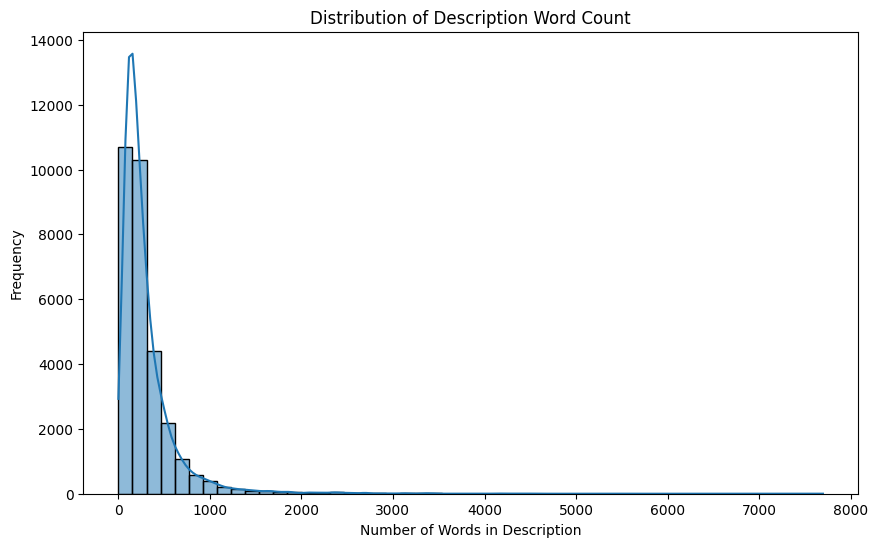

In [27]:
# Plot desc words
df["description_word_count"] = df["description"].apply(lambda x: len(str(x).split()))
plt.figure(figsize=(10, 6))
sns.histplot(df["description_word_count"], bins=50, kde=True)
plt.title("Distribution of Description Word Count")
plt.xlabel("Number of Words in Description")
plt.ylabel("Frequency")
plt.show()


In [28]:
# desc that have less than 15 words
short_desc = df[(df["description_word_count"] < 20) | (df["description_word_count"] > 800)]
short_desc[["title", "description", "description_word_count"]].head(33000)
# if description more than 800 words, take the first 800 words
df["description"] = df["description"].apply(lambda x: " ".join(str(x).split()[:800]))

In [ ]:
MIN_DESC_WORDS = 20

required_cols = ["description"]
missing_required = [c for c in required_cols if c in df.columns]

if "description" in df.columns:
    df["missing_description"] = df["description"].isna() | (df["description"].str.len() == 0)
    df["num_words_in_description"] = df["description"].fillna("").apply(lambda text: len(str(text).split()))

# Loc record thieu truong quan trong
if missing_required:
    before_rows = df.shape[0]
    df = df.dropna(subset=missing_required)
    print("Dropped missing required:", before_rows - df.shape[0])

# Loc mo ta qua ngan
if "num_words_in_description" in df.columns:
    before_rows = df.shape[0]
    df = df[df["num_words_in_description"] >= MIN_DESC_WORDS]
    print("Dropped short descriptions:", before_rows - df.shape[0])

print("After filters:", df.shape)

Dropped missing required: 0
Dropped short descriptions: 282
After filters: (30147, 22)


## 3c) EDA heatmap missing values
Kiem tra mat du lieu theo cot.

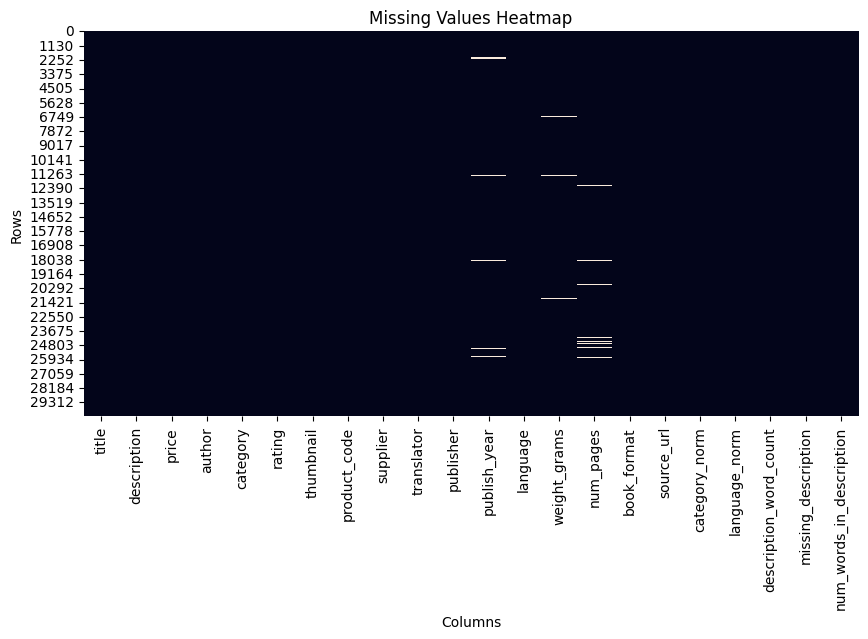

In [30]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False)
plt.title("Missing Values Heatmap")
plt.xlabel("Columns")
plt.ylabel("Rows")
plt.show()

## 3d) Correlation giua cac truong so
Dung Spearman de giam anh huong outliers.

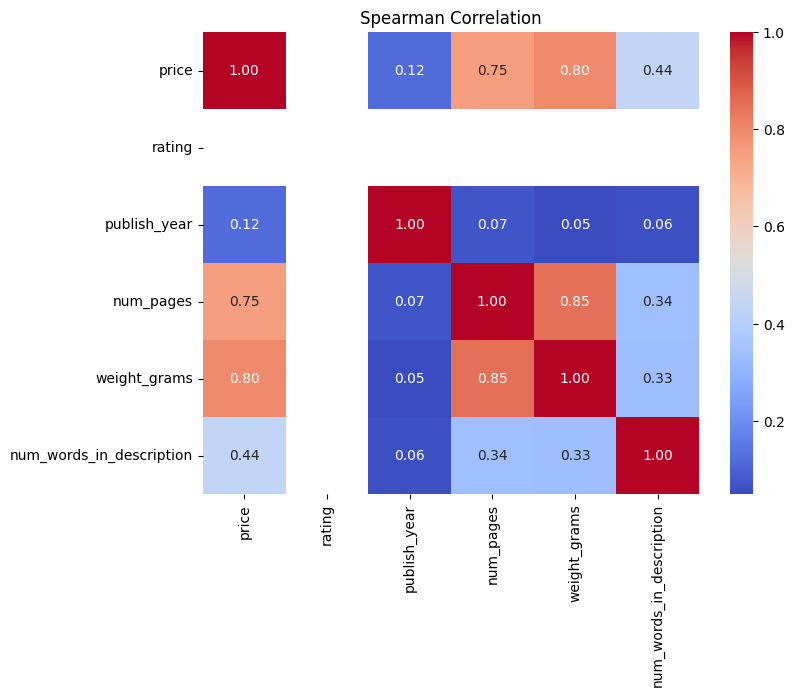

In [31]:
corr_cols = [c for c in ["price", "rating", "publish_year", "num_pages", "weight_grams", "num_words_in_description"] if c in df.columns]

if len(corr_cols) >= 2:
    corr = df[corr_cols].corr(method="spearman")
    plt.figure(figsize=(8, 6))
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Spearman Correlation")
    plt.show()
else:
    print("Not enough numeric columns for correlation.")

## 4) Xay dung logic chinh
Tao cac truong retrieval, doc_id va feature phuc vu filter/rerank.

In [32]:
import re
CURRENT_YEAR = 2026


def safe_str(value: str) -> str:
    if pd.isna(value):
        return ""
    return str(value)


def make_doc_id(row: pd.Series) -> str:
    if "source_url" in row and row.get("source_url"):
        return row.get("source_url")
    title = row.get("title", "")
    author = row.get("author", "")
    year = row.get("publish_year", "")
    return f"{title}|{author}|{year}"


def build_text(row: pd.Series, fields: list[str]) -> str:
    parts = [safe_str(row.get(f, "")) for f in fields]
    parts = [p for p in parts if p]
    return " | ".join(parts)


def extract_series_info(title: str):
    if pd.isna(title):
        return None, None

    text = str(title)
    patterns = [
        r"(.+?)\s*[-–]?\s*Tap\s*(\d+)",
        r"(.+?)\s*Vol\.?\s*(\d+)",
        r"(.+?)\s*#\s*(\d+)",
        r"(.+?)\s*[-–]?\s*Tập\s*(\d+)",
        r"(.+?)\s*[-–]?\s*tập\s*(\d+)",

    ]

    for pattern in patterns:
        match = re.search(pattern, text, re.IGNORECASE)
        if match:
            series = match.group(1).strip()
            volume = int(match.group(2))
            return series, volume

    return text.strip(), None


def add_features(df_in: pd.DataFrame) -> pd.DataFrame:
    df_out = df_in.copy()
    if "title" in df_out.columns:
        df_out[["series_name", "volume_number"]] = (
            df_out["title"].apply(lambda x: pd.Series(extract_series_info(x)))
        )
    if "publish_year" in df_out.columns:
        df_out["age"] = CURRENT_YEAR - df_out["publish_year"]
    if "price" in df_out.columns:
        df_out["price_bucket"] = pd.cut(
            df_out["price"],
            bins=[-1, 50000, 150000, 300000, np.inf],
            labels=["low", "mid", "high", "premium"],
        )
    if "rating" in df_out.columns:
        df_out["rating_bucket"] = pd.cut(
            df_out["rating"],
            bins=[-0.1, 2.5, 4.0, 5.0],
            labels=["low", "mid", "high"],
        )
    if "num_pages" in df_out.columns:
        df_out["pages_bucket"] = pd.cut(
            df_out["num_pages"],
            bins=[-1, 150, 350, 600, np.inf],
            labels=["short", "medium", "long", "very_long"],
        )
    if "translator" in df_out.columns:
        df_out["has_translator"] = df_out["translator"].astype(str).str.len() > 0
    if "language_norm" in df_out.columns:
        df_out["is_vietnamese"] = df_out["language_norm"].isin(["vi", "bilingual_en_vi", "bilingual_ja_vi", "bilingual_vi_ko"])
    return df_out


def build_retrieval_fields(df_in: pd.DataFrame) -> pd.DataFrame:
    df_out = df_in.copy()
    df_out["doc_id"] = df_out.apply(make_doc_id, axis=1)
    df_out["embedding_text"] = df_out.apply(
        lambda row: build_text(row, ["title", "author", "category_norm", "description"]),
        axis=1,
    )
    df_out["bm25_text"] = df_out.apply(
        lambda row: build_text(row, ["title", "author", "description"]),
        axis=1,
    )
    return df_out


df = add_features(df)
df = build_retrieval_fields(df)

cols_preview = [c for c in ["doc_id", "title", "author", "category_norm", "price", "rating", "publish_year", "num_pages", "series_name", "volume_number", "embedding_text"] if c in df.columns]
df[cols_preview].head(5)

,doc_id,title,author,category_norm,price,rating,publish_year,num_pages,series_name,volume_number,embedding_text
0,https://www.fahasa.com/1-2-3-5-bua-noi-tom-lai...,"1,2,3,5 Bữa - Nói Tóm Lại Ăn Thế Nào Là Tốt",Woo Won Yang,health,79000.0,5.0,20190.0,2690.0,"1,2,3,5 Bữa - Nói Tóm Lại Ăn Thế Nào Là Tốt",NaN,"1,2,3,5 Bữa - Nói Tóm Lại Ăn Thế Nào Là Tốt | ..."
1,https://www.fahasa.com/1-2-4-14-153-637350.html,Hình Dán Sticker Và Tô Màu - Tập 6,Trần Ngọc Bảo Hân,children_activity,18000.0,5.0,20250.0,200.0,Hình Dán Sticker Và Tô Màu,6.0,Hình Dán Sticker Và Tô Màu - Tập 6 | Trần Ngọc...
2,https://www.fahasa.com/1-2-4-14-153-637354.html,Hình Dán Sticker Và Tô Màu - Tập 10,Trần Ngọc Bảo Hân,children_activity,18000.0,5.0,20250.0,200.0,Hình Dán Sticker Và Tô Màu,10.0,Hình Dán Sticker Và Tô Màu - Tập 10 | Trần Ngọ...
3,https://www.fahasa.com/1-2-4-14-153.html,Hình Dán Sticker Và Tô Màu - Tập 1,Trần Ngọc Bảo Hân,children_activity,18000.0,5.0,20250.0,200.0,Hình Dán Sticker Và Tô Màu,1.0,Hình Dán Sticker Và Tô Màu - Tập 1 | Trần Ngọc...
4,https://www.fahasa.com/1-2-4-14-6238.html,Khám Phá Thế Giới Khủng Long - Những Bí Ẩn Thờ...,Jackie Nguyễn,children_magazine,91000.0,5.0,20240.0,880.0,Khám Phá Thế Giới Khủng Long - Những Bí Ẩn Thờ...,NaN,Khám Phá Thế Giới Khủng Long - Những Bí Ẩn Thờ...


## 5) Chay va hien thi ket qua
Tong hop EDA: duplicates, thong ke numeric, phan bo category/ngon ngu, do dai text.

In [33]:
eda_summary = []

eda_summary.append({"metric": "rows", "value": df.shape[0]})
eda_summary.append({"metric": "columns", "value": df.shape[1]})

if set(["title", "author"]).issubset(df.columns):
    dup_title_author = df.duplicated(subset=["title", "author"]).sum()
    eda_summary.append({"metric": "dup_title_author", "value": int(dup_title_author)})

if "source_url" in df.columns:
    dup_source = df.duplicated(subset=["source_url"]).sum()
    eda_summary.append({"metric": "dup_source_url", "value": int(dup_source)})

numeric_cols = [c for c in ["price", "rating", "publish_year", "num_pages", "weight_grams"] if c in df.columns]
for col in numeric_cols:
    stats = df[col].describe()
    eda_summary.append({"metric": f"{col}_min", "value": stats.get("min", np.nan)})
    eda_summary.append({"metric": f"{col}_max", "value": stats.get("max", np.nan)})
    eda_summary.append({"metric": f"{col}_median", "value": stats.get("50%", np.nan)})

if "category" in df.columns:
    print("Top categories:")
    print(df["category"].value_counts().head())

if "language" in df.columns:
    print("Top languages:")
    print(df["language"].value_counts().head(100))

if "thumbnail" in df.columns:
    thumb_missing = (df["thumbnail"].isna() | (df["thumbnail"].str.len() == 0)).mean()
    eda_summary.append({"metric": "thumbnail_missing_pct", "value": round(thumb_missing * 100, 2)})

for text_col in ["title", "description"]:
    if text_col in df.columns:
        lengths = df[text_col].fillna("").str.len()
        eda_summary.append({"metric": f"{text_col}_len_mean", "value": round(lengths.mean(), 2)})
        eda_summary.append({"metric": f"{text_col}_len_p95", "value": round(lengths.quantile(0.95), 2)})

eda_df = pd.DataFrame(eda_summary)
eda_df

Top categories:
category
Kỹ năng sống              2506
Manga Khác                2295
Truyện Đọc Thiếu Nhi      1551
Truyện Tranh Thiếu Nhi    1491
Tiểu thuyết               1351
Name: count, dtype: int64
Top languages:
language
                        17695
Tiếng Việt              12000
Song Ngữ Anh - Việt       185
Song Ngữ Nhật - Việt      119
Tiếng Anh                  92
Tiếng Trung                38
Tiếng Đức                   9
Song Ngữ Việt - Hàn         3
Tiếng Hàn                   3
Tiếng Tây Ban Nha           2
Tiếng Pháp                  1
Name: count, dtype: int64


,metric,value
0,rows,30147.00
1,columns,33.00
2,dup_title_author,113.00
3,dup_source_url,0.00
4,price_min,3120.00
5,price_max,5352000.00
6,price_median,63000.00
7,rating_min,5.00
8,rating_max,5.00
9,rating_median,5.00


In [34]:
#list all categories that have category_norm = 'other' and count
if "category_norm" in df.columns:
    other_categories = (
        df[df["category_norm"] == "other"]["category"]
        .value_counts()
        .reset_index()
        .rename(columns={"index": "original_category", "category": "count"})
    )
    print("Original categories mapped to 'other':")
    print(other_categories.head(200))

Original categories mapped to 'other':
           count  count
0  Thể loại khác     12
1                     1


## 6) Luu ket qua ra tep
Xuat file da xu ly va tagged descriptions cho retrieval.

In [35]:
processed_dir = Path("data/processed")
artifacts_dir = Path("data/artifacts")
processed_dir.mkdir(parents=True, exist_ok=True)
artifacts_dir.mkdir(parents=True, exist_ok=True)

processed_path = processed_dir / "books_processed.csv"
eda_path = processed_dir / "eda_summary.csv"
tagged_path = artifacts_dir / "tagged_descriptions.txt"

# Luu du lieu da xu ly
df.to_csv(processed_path, index=False)

# Luu summary EDA
eda_df.to_csv(eda_path, index=False)

# Luu tagged descriptions (ma sach + description)
if "description" in df.columns:
    with tagged_path.open("w", encoding="utf-8") as f:
        for _, row in df.iterrows():
            code = safe_str(row.get("product_code", ""))
            if not code:
                code = safe_str(row.get("doc_id", ""))
            desc = safe_str(row.get("description", ""))
            if code and desc:
                f.write(f"{code} {desc}\n")

print("Saved:")
print("-", processed_path)
print("-", eda_path)
print("-", tagged_path)

Saved:
- data\processed\books_processed.csv
- data\processed\eda_summary.csv
- data\artifacts\tagged_descriptions.txt
